# Transport, spallation, and adiabatic losses
Analyze the two outputs of `transport_spallation_loss.cpp` using NumPy and Matplotlib.

- `transport_spallation_loss.bin`: native-endian float64 records `(x, y, z, E, species_id)`; positions in pc, **total energy per nucleon** in GeV/n. Destroyed particles have ID −1 and retain their last position/energy in initial particle order.
- `earth_arrivals.bin`: native-endian float64 records `(E, species_id)`. Every step ending inside the solar-ring region contributes a record; the same particle can contribute many times. No particle ID or arrival time is saved.

The files contain no metadata. Parameters below describe the current source and must match the run. The simulation uses constant hydrogen density, a linear vertical wind, adiabatic cooling, and single-residual spallation without an escape boundary. It does not include continuous hadronic energy losses. Run from `output/` or the project directory.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 120})
data_dir = Path.cwd()
if not (data_dir / 'transport_spallation_loss.bin').exists():
    data_dir = data_dir / 'output'

# Run parameters: edit for binaries produced with other settings.
E_min, E_max = 10.0, 1e6  # injected total energy per nucleon, GeV/n
T_end = 1e8               # yr
a = 1e-8                  # div(u), yr^-1; u_z = a*z
m_p = 0.938272            # GeV/c^2
expected_particles = 210000
species_names = ['O16', 'N15', 'N14', 'C13', 'C12',
                 'B11', 'B10', 'Be10', 'Be9', 'Be7']
element_ids = {'O': [0], 'N': [1, 2], 'C': [3, 4],
               'B': [5, 6], 'Be': [7, 8, 9]}


def load_records(filename, columns):
    path = data_dir / filename
    if path.stat().st_size % (8 * columns):
        raise ValueError(f'{path}: incomplete float64 record')
    return np.fromfile(path, dtype='=f8').reshape(-1, columns)


particles = load_records('transport_spallation_loss.bin', 5)
arrivals = load_records('earth_arrivals.bin', 2)
x, y, z, E, species = particles.T
E_arr, species_arr = arrivals.T
tracked = species >= 0
N = len(E)
print(f'Data directory: {data_dir.resolve()}')
print(f'Final records: {N:,} (configured injection: {expected_particles:,})')
print(f'Tracked: {tracked.sum():,}; destroyed: {(~tracked).sum():,}')
print(f'Earth-arrival step samples: {len(arrivals):,}')
print('Final total energy range [GeV/n]:', E.min(), E.max())

Data directory: /Users/lichaomi/Downloads/research/CR_advection/Monte_Carlo/output
Final records: 210,000 (configured injection: 210,000)
Tracked: 61,341; destroyed: 148,659
Earth-arrival step samples: 1,646,960
Final total energy range [GeV/n]: 7.195925062116847 992077.2159913195


## Final abundances and sampled arrival composition
Final abundances count particles at the end of transport (or removal). Arrival composition counts step samples accumulated throughout propagation. These populations have different meanings; their normalizations should not be compared as survival probabilities.

   Species  Final particles   Arrival samples
 Destroyed          148,659                 0
       O16            6,238           706,281
       N15            3,888            25,055
       N14            3,262            82,694
       C13            2,765            11,593
       C12           15,947           736,755
       B11           11,706            41,871
       B10            6,606            17,945
      Be10            1,967             5,564
       Be9            3,518             7,240
       Be7            5,444            11,962


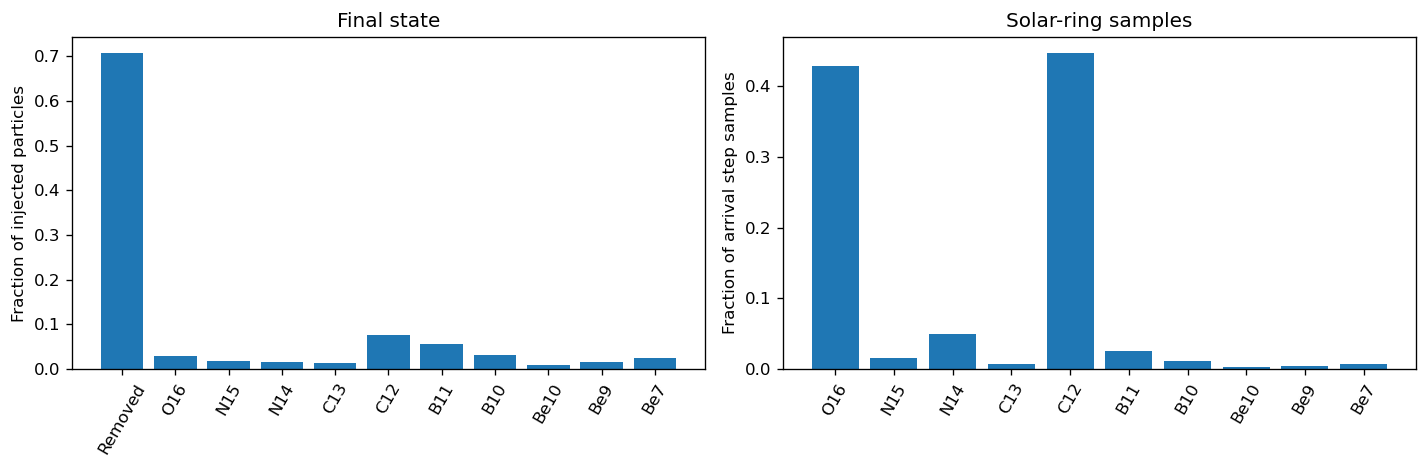

In [2]:
ids = np.arange(-1, 10)
final_counts = np.array([np.count_nonzero(species == i) for i in ids])
arrival_counts = np.array([np.count_nonzero(species_arr == i) for i in range(10)])
print(f'{"Species":>10} {"Final particles":>16} {"Arrival samples":>17}')
for label, count, arrival_count in zip(['Destroyed'] + species_names,
                                      final_counts, np.r_[0, arrival_counts]):
    print(f'{label:>10} {count:16,d} {arrival_count:17,d}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['Removed'] + species_names, final_counts / N)
axes[0].set_ylabel('Fraction of injected particles')
axes[0].set_title('Final state')
axes[1].bar(species_names, arrival_counts / max(len(arrivals), 1))
axes[1].set_ylabel('Fraction of arrival step samples')
axes[1].set_title('Solar-ring samples')
for ax in axes:
    ax.tick_params(axis='x', rotation=60)
fig.tight_layout()
plt.show()

## Energy spectra
The injected grid is uniform in log energy, rather than a physical source power law. Spectra below show raw counts per logarithmic energy interval, with no source reweighting or flux normalization. Removed-particle energies describe their destruction step, not the final simulation time.

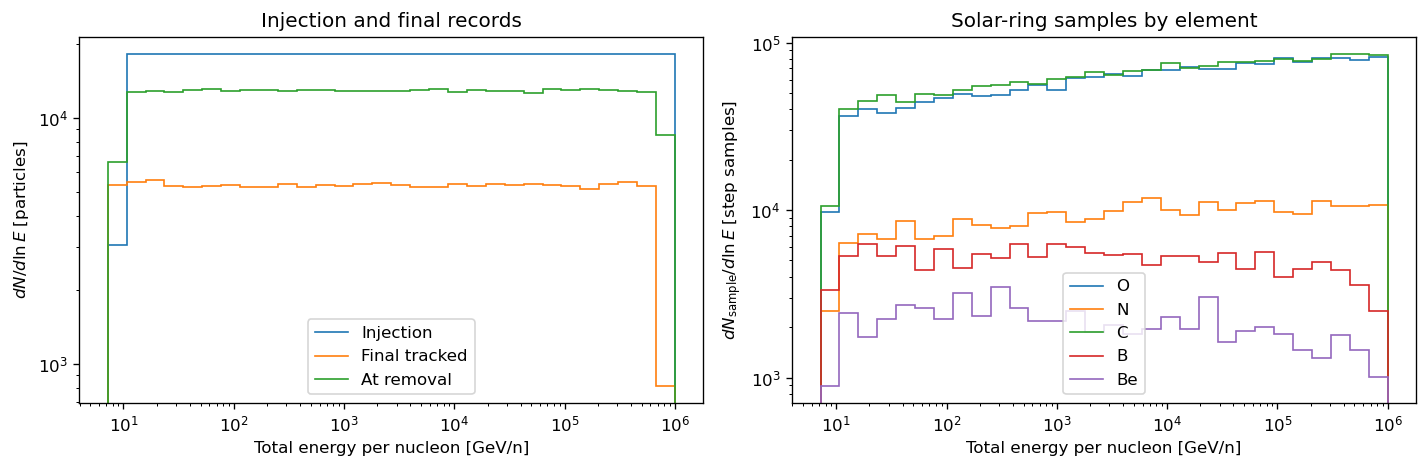

In [3]:
E0 = np.geomspace(E_min, E_max, N)  # output preserves injection order
energy_low = min(E.min(), E_arr.min() if len(E_arr) else E.min(), E_min)
energy_high = max(E.max(), E_arr.max() if len(E_arr) else E.max(), E_max)
bins = np.geomspace(energy_low * (1 - 1e-12), energy_high * (1 + 1e-12), 31)
Ec = np.sqrt(bins[:-1] * bins[1:])
dlnE = np.diff(np.log(bins))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for values, label in [(E0, 'Injection'), (E[tracked], 'Final tracked'),
                       (E[~tracked], 'At removal')]:
    counts, _ = np.histogram(values, bins)
    axes[0].stairs(counts / dlnE, bins, label=label)
for element, isotope_ids in element_ids.items():
    counts, _ = np.histogram(E_arr[np.isin(species_arr, isotope_ids)], bins)
    axes[1].stairs(counts / dlnE, bins, label=element)
for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total energy per nucleon [GeV/n]')
    ax.legend()
axes[0].set_ylabel(r'$dN/d\ln E$ [particles]')
axes[1].set_ylabel(r'$dN_{\mathrm{sample}}/d\ln E$ [step samples]')
axes[0].set_title('Injection and final records')
axes[1].set_title('Solar-ring samples by element')
fig.tight_layout()
plt.show()

## Boron-to-carbon ratio
Sum B10+B11 and C12+C13 in the same total-energy-per-nucleon bins. Empty carbon bins are omitted. The final-state ratio and the accumulated arrival-sample ratio are distinct diagnostics. Arrival samples are correlated within each particle, so independent Poisson error bars would not describe their uncertainty.

Final tracked particles: total B = 18,312, total C = 18,712
Solar-ring step samples: total B = 59,816, total C = 748,348


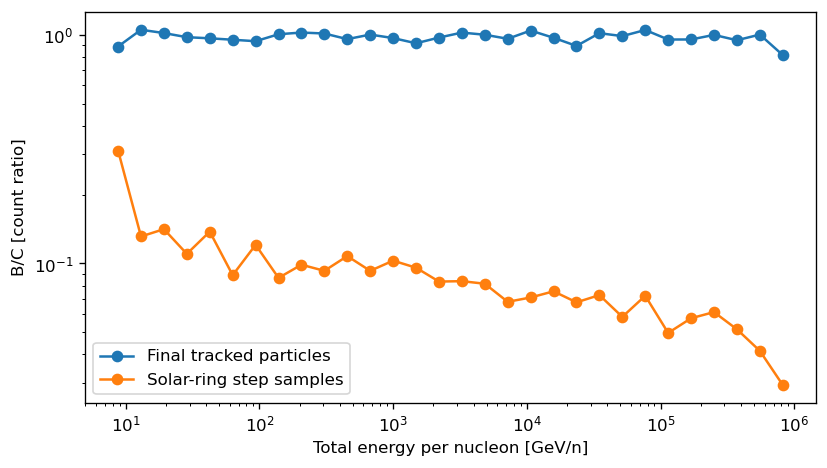

In [7]:
def element_counts(energies, species_ids, element):
    mask = np.isin(species_ids, element_ids[element])
    return np.histogram(energies[mask], bins)[0]


fig, ax = plt.subplots(figsize=(7, 4))
for energies, species_ids, label in [(E, species, 'Final tracked particles'),
                                    (E_arr, species_arr, 'Solar-ring step samples')]:
    B = element_counts(energies, species_ids, 'B')
    C = element_counts(energies, species_ids, 'C')
    ratio = np.divide(B, C, out=np.full(len(C), np.nan), where=C > 0)
    ax.semilogx(Ec, ratio, 'o-', label=label)
    print(f'{label}: total B = {B.sum():,}, total C = {C.sum():,}')
ax.set_xlabel('Total energy per nucleon [GeV/n]')
ax.set_ylabel('B/C [count ratio]')
ax.set_yscale("log")
ax.legend()
fig.tight_layout()
plt.show()

## Adiabatic cooling
For constant divergence $a$, $p(t)=p_0\exp(-at/3)$, hence
$$E(t)=\sqrt{m_p^2+(E_0^2-m_p^2)e^{-2at/3}}.$$
Tracked particles evolve until $T_{\rm end}$; removed particles stop earlier. Inferring elapsed times from energy assumes the configured initial energy grid and constant divergence. Initial species and positions cannot be recovered from these files; arrival records cannot be linked to final particles.

Max |relative energy residual|, tracked: 3.7983934938872863e-10
Inferred time min / median / max [Myr]: [5.77278742e-04 5.77351015e+01 1.00000000e+02]


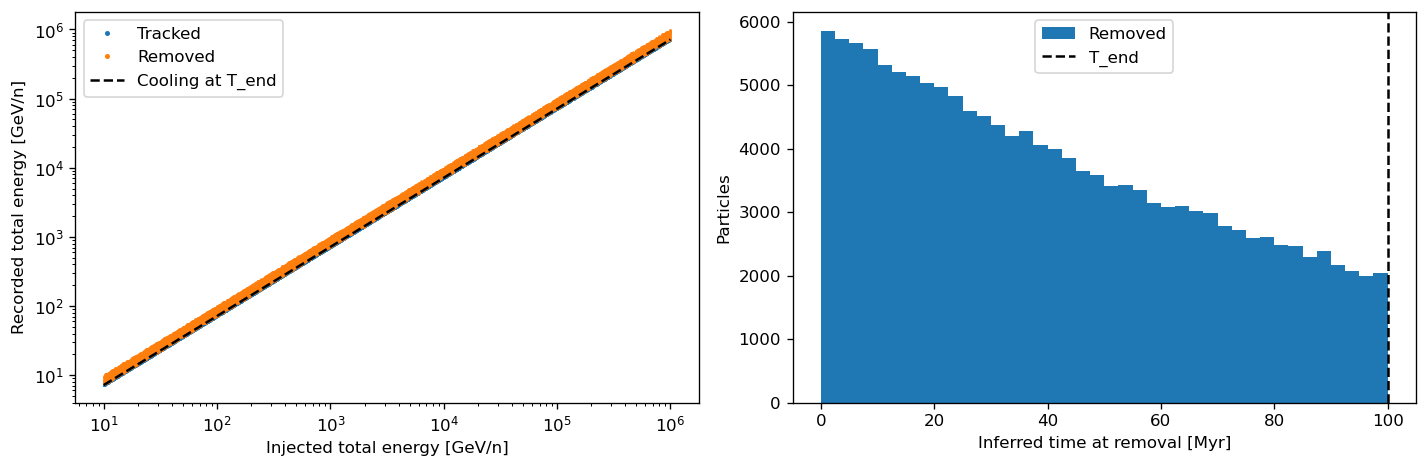

In [5]:
E_reference = np.sqrt(m_p**2 + (E0**2 - m_p**2) * np.exp(-2*a*T_end/3))
p0 = np.sqrt(E0**2 - m_p**2)
p = np.sqrt(E**2 - m_p**2)
t_inferred = -3.0 / a * np.log(p / p0)  # yr; assumes a != 0
if tracked.any():
    residual = (E[tracked] - E_reference[tracked]) / E_reference[tracked]
    print('Max |relative energy residual|, tracked:', np.max(np.abs(residual)))
print('Inferred time min / median / max [Myr]:',
      np.percentile(t_inferred / 1e6, [0, 50, 100]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stride = max(1, N // 15000)
idx = np.arange(0, N, stride)
for mask, label in [(tracked, 'Tracked'), (~tracked, 'Removed')]:
    selected = idx[mask[idx]]
    axes[0].loglog(E0[selected], E[selected], '.', ms=1, label=label)
axes[0].loglog(E0, E_reference, 'k--', label='Cooling at T_end')
axes[0].set_xlabel('Injected total energy [GeV/n]')
axes[0].set_ylabel('Recorded total energy [GeV/n]')
axes[0].legend(markerscale=4)
axes[1].hist(t_inferred[~tracked] / 1e6, bins=40, label='Removed')
axes[1].axvline(T_end / 1e6, color='k', ls='--', label='T_end')
axes[1].set_xlabel('Inferred time at removal [Myr]')
axes[1].set_ylabel('Particles')
axes[1].legend()
fig.tight_layout()
plt.show()

## Spatial distribution of tracked particles
Positions below use kpc. Removed particles are excluded because their coordinates freeze at destruction. The solar-ring selection is centered on $R=8$ kpc, $z=0$, with an energy-dependent radius $\lambda(E)=2E^{1/3}$ pc; it is a ring rather than a point detector. Final positions do not reconstruct arrival trajectories.

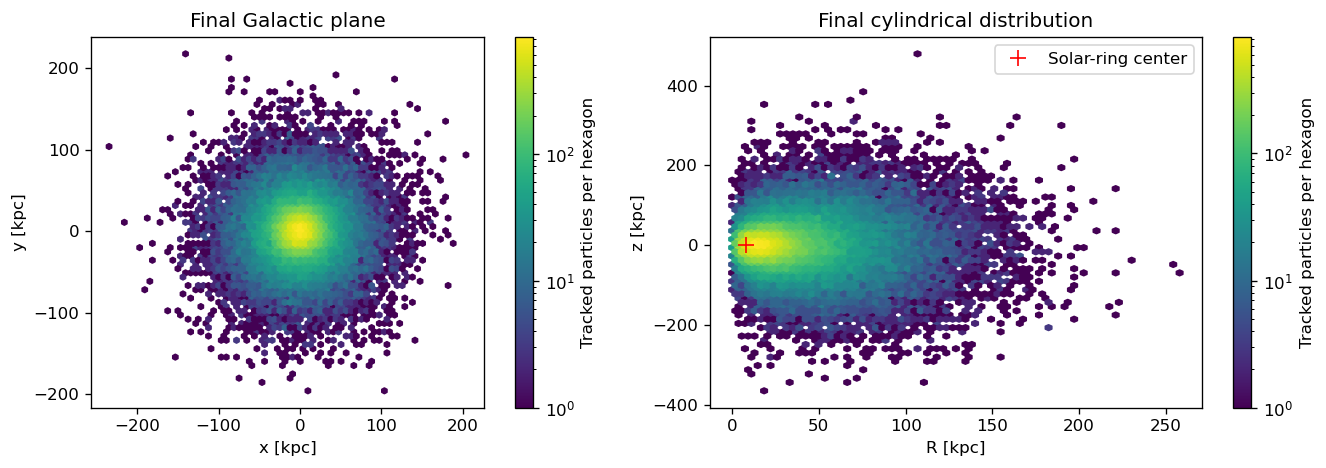

In [6]:
R = np.hypot(x, y) / 1000.0
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if tracked.any():
    image = axes[0].hexbin(x[tracked] / 1000, y[tracked] / 1000,
                          gridsize=70, bins='log', mincnt=1)
    fig.colorbar(image, ax=axes[0], label='Tracked particles per hexagon')
    image = axes[1].hexbin(R[tracked], z[tracked] / 1000,
                          gridsize=70, bins='log', mincnt=1)
    fig.colorbar(image, ax=axes[1], label='Tracked particles per hexagon')
axes[0].set(xlabel='x [kpc]', ylabel='y [kpc]', title='Final Galactic plane')
axes[0].set_aspect('equal')
axes[1].plot(8.0, 0.0, 'r+', ms=10, label='Solar-ring center')
axes[1].set(xlabel='R [kpc]', ylabel='z [kpc]', title='Final cylindrical distribution')
axes[1].legend()
fig.tight_layout()
plt.show()